# A quantum time-series transformer on resting-state fMRI: autism vs control (ABIDE I)

This notebook applies a **quantum time-series transformer** (QTSTransformer; Park et al., 2025) to public resting-state fMRI data and compares it with classical models that have the **same number of trainable parameters**.

**The question.** With few participants, large neural networks memorise their training data. A quantum model with ~20,000 parameters can look better than a classical transformer with millions of parameters, but that comparison cannot tell whether the advantage comes from the quantum structure or simply from being small. Here we compare against classical models of the same size.

**This notebook is self-contained.** Every piece of code is in it: data download, data preparation, the quantum model, the classical models, and the training loop. Everything runs on a CPU; the quantum circuits are simulated exactly with PennyLane, so no quantum hardware is needed.

References
- Park, J. J., Seo, J., Bae, S., Chen, S. Y.-C., Tseng, H.-H., Cha, J., & Yoo, S. (2025). Resting-state fMRI analysis using quantum time-series transformer. *2025 IEEE International Conference on Quantum Computing and Engineering (QCE)*. https://arxiv.org/abs/2509.00711
- Khatri, N., Matos, G., Coopmans, L., & Clark, S. (2024). Quixer: A quantum transformer model. *arXiv:2406.04305*.
- Di Martino, A., Yan, C.-G., Li, Q., Denio, E., Castellanos, F. X., Alaerts, K., ... Milham, M. P. (2014). The autism brain imaging data exchange: Towards a large-scale evaluation of the intrinsic brain architecture in autism. *Molecular Psychiatry, 19*(6), 659–667. https://doi.org/10.1038/mp.2013.78
- Craddock, C., Benhajali, Y., Chu, C., Chouinard, F., Evans, A., Jakab, A., Khundrakpam, B. S., Lewis, J. D., Li, Q., Milham, M., Yan, C., & Bellec, P. (2013). The Neuro Bureau Preprocessing Initiative: Open sharing of preprocessed neuroimaging data and derivatives. *Frontiers in Neuroinformatics*.

## 0. Setup

Required packages: `pennylane torch scikit-learn pandas matplotlib`. On Google Colab, install PennyLane first in a new cell with `%pip install pennylane`.

In [1]:
import os
import random
import urllib.request
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pennylane as qml
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

# Use the project's data folder if it exists (local run), otherwise download next to the notebook.
DATA_DIR = os.path.abspath("../data/nilearn_data" if os.path.isdir("../data/nilearn_data") else "./abide_data")
SEQ_LEN = 116  # time points per participant (section 3)
N_QUBITS = 8
torch.set_num_threads(8)  # same thread count as the runs behind the saved results
print("PennyLane", qml.__version__, "| PyTorch", torch.__version__, "| data folder:", os.path.relpath(DATA_DIR))

PennyLane 0.42.3 | PyTorch 2.9.1+cu130 | data folder: ../data/nilearn_data


## 1. Data: ABIDE I preprocessed ROI time series

The Autism Brain Imaging Data Exchange (ABIDE I) shares resting-state fMRI from 17 international sites. The Preprocessed Connectomes Project provides already-preprocessed **region-of-interest (ROI) time series**: for each participant, a table with one row per time point (one fMRI volume) and one column per brain region.

Settings used here: C-PAC pipeline, band-pass filtered (0.01–0.1 Hz), no global signal regression, Craddock 200 atlas (200 regions), quality-checked participants only. The data are free to download without an application; they are shared for non-commercial research (CC BY-NC-SA), so each user downloads them directly from the source.

`nilearn.datasets.fetch_abide_pcp` downloads the same files but one at a time, which can take hours because the server limits the speed of each connection. The function below downloads them in parallel into the same folder layout, so nilearn also recognises them afterwards. Files that already exist are skipped.

In [2]:
ABIDE_URL = "https://s3.amazonaws.com/fcp-indi/data/Projects/ABIDE_Initiative"


def quality_checked(phenotype: pd.DataFrame) -> pd.DataFrame:
    """nilearn's `quality_checked=True` rule: all raters passed the scan, and a preprocessed file exists."""
    keep = (
        (phenotype["FILE_ID"] != "no_filename")
        & (phenotype["qc_rater_1"] == "OK")
        & phenotype["qc_anat_rater_2"].isin(["OK", "maybe"])
        & phenotype["qc_func_rater_2"].isin(["OK", "maybe"])
        & (phenotype["qc_anat_rater_3"] == "OK")
        & (phenotype["qc_func_rater_3"] == "OK")
    )
    return phenotype.loc[keep].copy()


def download_abide(data_dir: str, workers: int = 24) -> None:
    root = os.path.join(data_dir, "ABIDE_pcp")
    ts_dir = os.path.join(root, "cpac", "filt_noglobal")
    os.makedirs(ts_dir, exist_ok=True)
    csv_path = os.path.join(root, "Phenotypic_V1_0b_preprocessed1.csv")
    if not os.path.exists(csv_path):
        urllib.request.urlretrieve(f"{ABIDE_URL}/Phenotypic_V1_0b_preprocessed1.csv", csv_path)
    file_ids = quality_checked(pd.read_csv(csv_path))["FILE_ID"].tolist()

    def fetch(file_id):
        name = f"{file_id}_rois_cc200.1D"
        dest = os.path.join(ts_dir, name)
        if not os.path.exists(dest):
            urllib.request.urlretrieve(f"{ABIDE_URL}/Outputs/cpac/filt_noglobal/rois_cc200/{name}", dest + ".part")
            os.replace(dest + ".part", dest)  # a file appears only once it is complete

    with ThreadPoolExecutor(max_workers=workers) as pool:
        list(pool.map(fetch, file_ids))
    print(f"{len(file_ids)} quality-checked participants; time series in {os.path.relpath(ts_dir)}")


download_abide(DATA_DIR)

871 quality-checked participants; time series in ../data/nilearn_data/ABIDE_pcp/cpac/filt_noglobal


## 2. The outcome variable

We predict **`DX_GROUP`**, the diagnostic group. In the official ABIDE data legend (ABIDE_LEGEND_V1.02) it is coded 1 = Autism, 2 = Control. We recode it as **y = 1 for autism and y = 0 for control**, so the task is **binary classification** and the metric is the area under the ROC curve (AUROC; 0.5 = chance, 1.0 = perfect).

Why not another variable? The counts below come from the quality-checked participants.

In [3]:
pheno = quality_checked(pd.read_csv(os.path.join(DATA_DIR, "ABIDE_pcp", "Phenotypic_V1_0b_preprocessed1.csv")))
num = lambda c: pd.to_numeric(pheno[c], errors="coerce").replace(-9999, np.nan)  # noqa: E731
candidates = pd.DataFrame([
    ["DX_GROUP", "diagnosis: 1 = autism, 2 = control", "binary classification", num("DX_GROUP").notna().sum(),
     "no missing values; the standard ABIDE task (used here)"],
    ["DSM_IV_TR", "0 = control, 1 = autism, 2 = Asperger, 3 = PDD-NOS, 4 = Asperger or PDD-NOS", "multi-class classification",
     num("DSM_IV_TR").notna().sum(), "small subtype groups and site-dependent diagnostic practice"],
    ["ADOS_TOTAL", "autism symptom severity (0-22)", "regression", num("ADOS_TOTAL").notna().sum(),
     "available mostly for autistic participants only"],
    ["SEX", "1 = male, 2 = female", "binary classification", num("SEX").notna().sum(),
     f"strongly imbalanced ({(num('SEX') == 1).sum()} male vs {(num('SEX') == 2).sum()} female)"],
], columns=["variable", "coding (ABIDE legend)", "task type", "non-missing", "comment"])
print("DX_GROUP counts:", num("DX_GROUP").map({1: "autism", 2: "control"}).value_counts().to_dict())
print("DSM_IV_TR counts:", num("DSM_IV_TR").value_counts(dropna=False).sort_index().to_dict())
candidates

DX_GROUP counts: {'control': 468, 'autism': 403}
DSM_IV_TR counts: {0.0: 456, 1.0: 258, 2.0: 74, 3.0: 29, 4.0: 1, nan: 53}


,variable,coding (ABIDE legend),task type,non-missing,comment
0,DX_GROUP,"diagnosis: 1 = autism, 2 = control",binary classification,871,no missing values; the standard ABIDE task (us...
1,DSM_IV_TR,"0 = control, 1 = autism, 2 = Asperger, 3 = PDD...",multi-class classification,818,small subtype groups and site-dependent diagno...
2,ADOS_TOTAL,autism symptom severity (0-22),regression,301,available mostly for autistic participants only
3,SEX,"1 = male, 2 = female",binary classification,871,strongly imbalanced (727 male vs 144 female)


## 3. Data preparation: who is included, and how long is each scan?

Sites recorded scans of different lengths (78 to 316 time points) with different repetition times. A transformer needs the same number of time points for everyone, so each scan is cropped to its central `SEQ_LEN` time points. Scans shorter than `SEQ_LEN` are excluded, and the report counts them so that the sample never shrinks silently.

We use `SEQ_LEN = 116`. This excludes only the one site whose scans have 78 time points, while every other participant keeps at least 116. (`SEQ_LEN = 78` would keep everyone with shorter scans.)

Each region's signal is then z-scored within each participant, because raw BOLD amplitude differs between scanners.

In [4]:
OUTCOME_CODING = {1: 1, 2: 0}  # DX_GROUP: 1 = autism -> y = 1, 2 = control -> y = 0


def scan_cohort(data_dir: str, seq_len: int):
    """List usable participants and report every exclusion. Returns (entries, report)."""
    root = os.path.join(data_dir, "ABIDE_pcp")
    ts_dir = os.path.join(root, "cpac", "filt_noglobal")
    qc = quality_checked(pd.read_csv(os.path.join(root, "Phenotypic_V1_0b_preprocessed1.csv")))
    report = dict(quality_checked=len(qc), file_found=0, empty=0, too_short=0, lengths={})
    entries = []
    for _, row in qc.iterrows():
        path = os.path.join(ts_dir, f"{row['FILE_ID']}_rois_cc200.1D")
        if not os.path.exists(path):
            continue
        report["file_found"] += 1
        arr = np.loadtxt(path, comments="#")
        if arr.ndim != 2 or arr.shape[0] == 0:
            report["empty"] += 1
            continue
        report["lengths"][arr.shape[0]] = report["lengths"].get(arr.shape[0], 0) + 1
        if arr.shape[0] < seq_len:
            report["too_short"] += 1
            continue
        entries.append(dict(file_id=row["FILE_ID"], site=row["SITE_ID"], path=path,
                            y=float(OUTCOME_CODING[int(row["DX_GROUP"])])))
    report["used"] = len(entries)
    return entries, report


def load_arrays(entries, seq_len: int):
    """Crop each scan to its central seq_len time points and z-score every region within the participant.

    Returns X of shape (participants, seq_len, 200) and y of shape (participants,).
    Regions with zero variance in a participant (no coverage) become all zeros.
    """
    xs = []
    for e in entries:
        arr = np.loadtxt(e["path"], comments="#")
        start = (arr.shape[0] - seq_len) // 2
        arr = arr[start : start + seq_len]
        sd = arr.std(axis=0, keepdims=True)
        arr = np.where(sd > 0, (arr - arr.mean(axis=0, keepdims=True)) / np.where(sd > 0, sd, 1.0), 0.0)
        xs.append(arr.astype(np.float32))
    return np.stack(xs), np.array([e["y"] for e in entries], dtype=np.float32)


def subsample(entries, n_subjects: int, seed: int):
    """Draw n_subjects participants, stratified by diagnosis; a new draw for every seed. 0 = everyone."""
    if n_subjects <= 0 or n_subjects >= len(entries):
        return entries
    y = np.array([e["y"] for e in entries])
    keep, _ = train_test_split(np.arange(len(entries)), train_size=n_subjects, random_state=seed, stratify=y)
    return [entries[i] for i in keep]


def split_indices(y, seed: int):
    """70 / 15 / 15 train / validation / test split, stratified by diagnosis."""
    idx_tr, idx_tmp = train_test_split(np.arange(len(y)), test_size=0.30, random_state=seed, stratify=y)
    idx_va, idx_te = train_test_split(idx_tmp, test_size=0.50, random_state=seed, stratify=y[idx_tmp])
    return idx_tr, idx_va, idx_te


def make_loaders(X, y, batch_size: int, seed: int):
    idx_tr, idx_va, idx_te = split_indices(y, seed)

    def build(idx, shuffle):
        ds = TensorDataset(torch.tensor(X[idx]), torch.tensor(y[idx]))
        return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, generator=torch.Generator().manual_seed(seed))

    return build(idx_tr, True), build(idx_va, False), build(idx_te, False), (len(idx_tr), len(idx_va), len(idx_te))


entries, report = scan_cohort(DATA_DIR, SEQ_LEN)
y_all = np.array([e["y"] for e in entries])
print(f"quality-checked participants : {report['quality_checked']}")
print(f"time-series file found       : {report['file_found']}")
print(f"empty file (excluded)        : {report['empty']}")
print(f"shorter than {SEQ_LEN} (excluded) : {report['too_short']}")
print(f"participants used            : {report['used']}  (autism {int(y_all.sum())}, control {int((1 - y_all).sum())})")
print("scan lengths (most common)   :", sorted(report["lengths"].items(), key=lambda kv: -kv[1])[:8])
sites = pd.DataFrame(entries).groupby("site")["y"].agg(autism="sum", n="count")
sites["control"] = sites["n"] - sites["autism"]
sites[["autism", "control"]].astype(int).T

quality-checked participants : 871
time-series file found       : 871
empty file (excluded)        : 0
shorter than 116 (excluded) : 25
participants used            : 846  (autism 391, control 455)
scan lengths (most common)   : [(176, 211), (196, 129), (296, 120), (116, 119), (236, 86), (146, 59), (246, 56), (152, 29)]


site,CALTECH,CMU,KKI,LEUVEN_1,LEUVEN_2,MAX_MUN,NYU,OLIN,PITT,SBL,SDSU,STANFORD,TRINITY,UCLA_1,UCLA_2,UM_1,UM_2,USM,YALE
autism,5,6,12,14,12,19,74,14,24,12,8,12,19,37,11,34,13,43,22
control,10,5,21,14,16,27,98,14,26,14,19,13,25,27,10,52,21,24,19


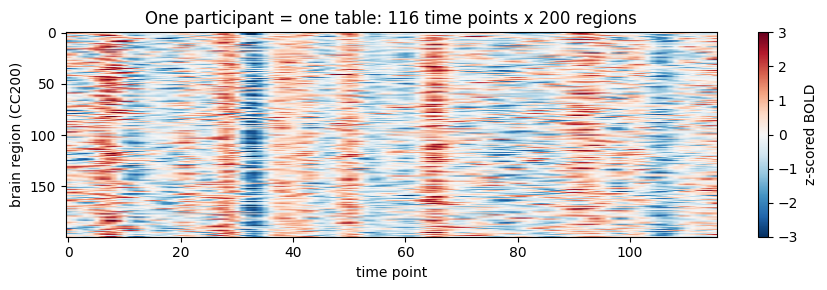

In [5]:
X_one, _ = load_arrays(entries[:1], SEQ_LEN)
plt.figure(figsize=(9, 3))
plt.imshow(X_one[0].T, aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3)
plt.xlabel("time point"); plt.ylabel("brain region (CC200)"); plt.colorbar(label="z-scored BOLD")
plt.title("One participant = one table: 116 time points x 200 regions")
plt.tight_layout(); plt.savefig("abide_one_participant.png", dpi=300); plt.show()

## 4. The quantum time-series transformer

The model reads the table one time point at a time and mixes time points the way attention does in a classical transformer, but with quantum operations. The code in this section is the model behind the saved results (section 7 checks this).

### 4.1 One time point becomes one quantum circuit

A linear layer turns the 200 regional values at time point *t* into rotation angles. The angles fill a fixed circuit layout ("circuit 14" of Sim, Johnson, & Aspuru-Guzik, 2019): single-qubit rotations about Y (`RY`) and controlled rotations about X (`CRX`) that link neighbouring qubits in a ring. With these angles the circuit is a unitary operation *U_t*: each time point becomes a quantum operation. The diagram below shows one layer of this circuit on the 8 qubits used in the experiments; each time point uses three layers.

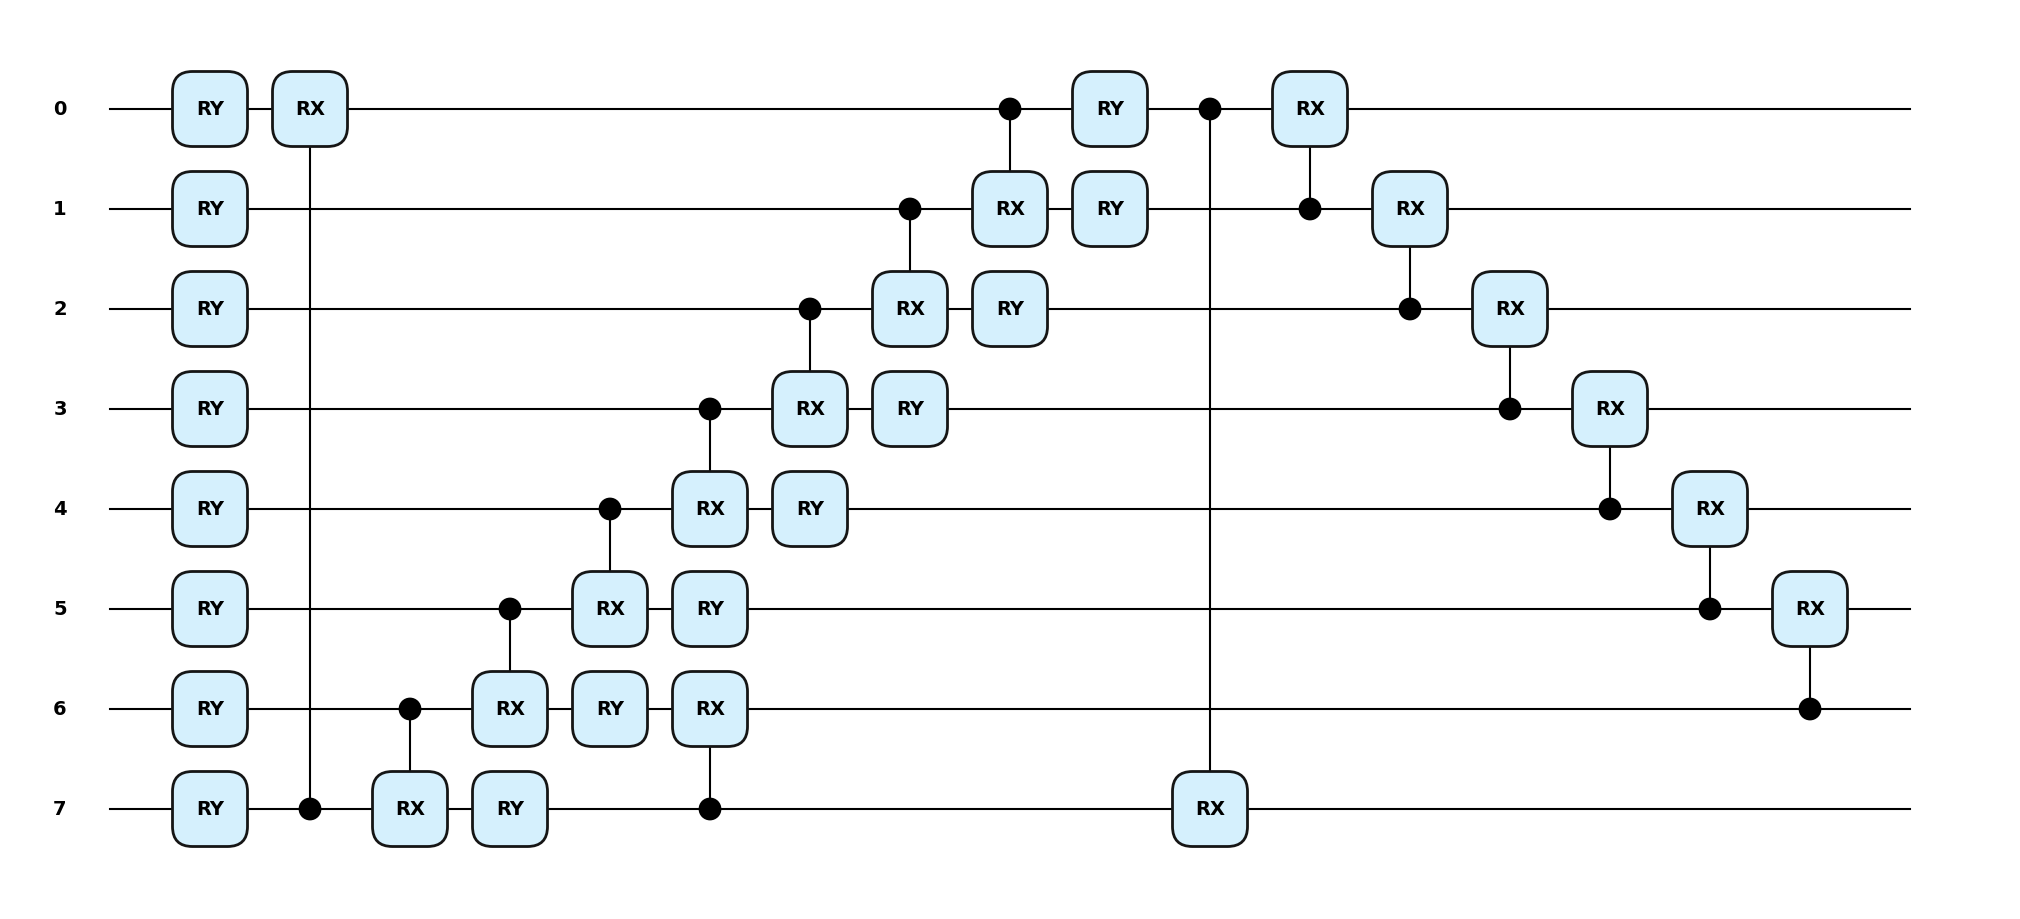

In [6]:
def sim14_circuit(params, wires, layers=1):
    """Circuit 14 of Sim et al. (2019). `params` holds 4 * wires * layers angles (a batch of them is allowed)."""
    is_batched = params.ndim == 2
    idx = 0

    def take():
        nonlocal idx
        angle = params[:, idx] if is_batched else params[idx]
        idx += 1
        return angle

    for _ in range(layers):
        for i in range(wires):
            qml.RY(take(), wires=i)
        for i in range(wires - 1, -1, -1):
            qml.CRX(take(), wires=[i, (i + 1) % wires])
        for i in range(wires):
            qml.RY(take(), wires=i)
        for i in [wires - 1] + list(range(wires - 1)):
            qml.CRX(take(), wires=[i, (i - 1) % wires])


# One layer of circuit 14 on the 8 qubits used in the experiments (each time point uses three such layers).
fig, ax = qml.draw_mpl(lambda p: sim14_circuit(p, wires=N_QUBITS, layers=1), decimals=None, style="pennylane")(
    torch.zeros(4 * N_QUBITS)
)
fig.savefig(f"qtst_circuit14_{N_QUBITS}qubits.png", dpi=300, bbox_inches="tight")
plt.show()

### 4.2 Mixing time points: linear combination of unitaries (LCU)

Attention in a transformer lets every time point look at every other one. Here the role is played by a *linear combination of unitaries*: a weighted sum of all time-point circuits, **M = Σ_t α_t U_t**, with one learned complex weight α_t per time point. Applying M to a quantum state gives a state that carries information from all time points at once.

In this simulation every *U_t* is applied to the state and the results are added with the weights. On quantum hardware the same sum would be prepared with extra (ancilla) qubits and post-selection.

In [7]:
def apply_lcu_mixing(base_states, unitary_params, qnode_state, coeffs):
    """Return sum_t coeffs[t] * U_t |state> for every participant in the batch.

    base_states: (batch, 2**n_qubits) state vectors; unitary_params: (batch, time, n_angles).
    All (participant x time point) circuits are run as one batch.
    """
    bsz, n_timesteps, _ = unitary_params.shape
    n_amplitudes = base_states.shape[1]

    flat_params = unitary_params.reshape(bsz * n_timesteps, -1)
    repeated = base_states.repeat_interleave(n_timesteps, dim=0)

    evolved = qnode_state(initial_state=repeated, params=flat_params)
    evolved = evolved.reshape(bsz, n_timesteps, n_amplitudes).to(torch.complex64)

    return torch.einsum("bti,bt->bi", evolved, coeffs.to(torch.complex64))

### 4.3 Non-linearity: a polynomial of M (quantum singular value transformation)

A transformer needs non-linear steps. Quantum singular value transformation (QSVT) applies a polynomial to an operator; here **P(M) = c_0 I + c_1 M + c_2 M²** with learned coefficients c_k. The M² term lets pairs of time points interact, much as stacking attention layers does.

In [8]:
def apply_qsvt_polynomial(base_states, unitary_params, qnode_state, lcu_coeffs, poly_coeffs):
    """Return P(M)|state> = sum_k c_k M^k |state>, divided by sum_k |c_k|."""
    acc = poly_coeffs[0] * base_states
    working = base_states
    for c in poly_coeffs[1:]:
        working = apply_lcu_mixing(working, unitary_params, qnode_state, lcu_coeffs)
        acc = acc + c * working
    return acc / torch.linalg.vector_norm(poly_coeffs, ord=1)

### 4.4 The full model

Start every participant in the all-zero state |00…0⟩, apply P(M), renormalise, pass the state through one more trainable circuit (the quantum feed-forward layer), and measure Pauli X, Y and Z on every qubit. The 3 × n_qubits measured values go into a linear layer that gives the logit for "autism".

In [9]:
class QuantumTSTransformer(nn.Module):
    """Quantum time-series transformer. Input (batch, time points, features) -> output (batch,) logits."""

    def __init__(self, n_qubits, n_timesteps, degree, n_ansatz_layers, feature_dim, output_dim, dropout, device):
        super().__init__()
        self.n_qubits = n_qubits
        self.n_timesteps = n_timesteps
        self.degree = degree
        self.n_ansatz_layers = n_ansatz_layers
        self.device = device

        self.n_rots = 4 * n_qubits * n_ansatz_layers  # angles of one time-point circuit
        self.qff_n_rots = 4 * n_qubits  # angles of the feed-forward circuit

        self.feature_projection = nn.Linear(feature_dim, self.n_rots)  # 200 regional values -> angles
        self.dropout = nn.Dropout(dropout)
        self.rot_sigm = nn.Sigmoid()
        self.output_ff = nn.Linear(3 * n_qubits, output_dim)  # measured values -> logit

        self.poly_coeffs = nn.Parameter(torch.rand(degree + 1))  # c_0 ... c_degree
        self.mix_coeffs = nn.Parameter(torch.rand(n_timesteps, dtype=torch.complex64))  # alpha_t
        self.qff_params = nn.Parameter(torch.rand(self.qff_n_rots))

        self.dev = qml.device("default.qubit", wires=n_qubits)
        n_wires, n_layers = n_qubits, n_ansatz_layers

        @qml.qnode(self.dev, interface="torch", diff_method="backprop")
        def _timestep_state(initial_state, params):
            qml.StatePrep(initial_state, wires=range(n_wires))
            sim14_circuit(params, wires=n_wires, layers=n_layers)
            return qml.state()

        self.timestep_state_qnode = _timestep_state

        @qml.qnode(self.dev, interface="torch", diff_method="backprop")
        def _qff_expval(initial_state, params):
            qml.StatePrep(initial_state, wires=range(n_wires))
            sim14_circuit(params, wires=n_wires, layers=1)
            obs = (
                [qml.PauliX(i) for i in range(n_wires)]
                + [qml.PauliY(i) for i in range(n_wires)]
                + [qml.PauliZ(i) for i in range(n_wires)]
            )
            return [qml.expval(o) for o in obs]

        self.qff_qnode_expval = _qff_expval

    def forward(self, x):
        bsz = x.shape[0]
        timestep_params = self.rot_sigm(self.feature_projection(self.dropout(x)))  # angles in (0, 1)

        base_states = torch.zeros(bsz, 2**self.n_qubits, dtype=torch.complex64, device=x.device)
        base_states[:, 0] = 1.0  # |00...0>

        mixed = apply_qsvt_polynomial(
            base_states, timestep_params, self.timestep_state_qnode,
            self.mix_coeffs.repeat(bsz, 1), self.poly_coeffs,
        )
        mixed = mixed / (torch.linalg.vector_norm(mixed, dim=1, keepdim=True) + 1e-9)

        exps = torch.stack(self.qff_qnode_expval(initial_state=mixed, params=self.qff_params), dim=1)
        return self.output_ff(exps.float()).squeeze(-1)


def count_trainable_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def build_quantum(n_timesteps=SEQ_LEN, feature_dim=200, n_qubits=N_QUBITS):
    return QuantumTSTransformer(n_qubits=n_qubits, n_timesteps=n_timesteps, degree=2, n_ansatz_layers=3,
                                feature_dim=feature_dim, output_dim=1, dropout=0.1, device=torch.device("cpu"))


qmodel = build_quantum()
with torch.no_grad():
    print("input (participants, time points, regions):", tuple(X_one.shape),
          "-> output logit:", qmodel(torch.tensor(X_one)).numpy())
print(f"trainable parameters: {count_trainable_parameters(qmodel):,}")
pd.Series({name: p.numel() for name, p in qmodel.named_parameters()}, name="parameters").to_frame()

input (participants, time points, regions): (1, 116, 200) -> output logit: [0.17756477]
trainable parameters: 19,472


,parameters
poly_coeffs,3
mix_coeffs,116
qff_params,32
feature_projection.weight,19200
feature_projection.bias,96
output_ff.weight,24
output_ff.bias,1


Most of the quantum model's parameters sit in the classical input projection (200 regional values → 96 circuit angles); the quantum part itself (mixing weights, polynomial, feed-forward circuit) has 151.

## 5. Classical models of the same size

| Model | Looks at | Parameters |
| --- | --- | --- |
| Classical transformer | the order of time points, mixed by self-attention; width shrunk to match the quantum model | ≈19,600 |
| Functional connectivity + logistic regression | which regions fluctuate together (Pearson correlation of every region pair), not the order of time points; the standard approach for ABIDE | 19,901 |

The width of the classical transformer is chosen automatically so that its parameter count is as close as possible to the quantum model's.

In [10]:
def _pick_nhead(d_model: int) -> int:
    for h in (8, 6, 4, 3, 2, 1):
        if d_model % h == 0:
            return h
    return 1


class SmallTransformer(nn.Module):
    """Classical self-attention transformer with a reduced width (no positional embedding)."""

    def __init__(self, feature_dim, d_model=42, n_layers=1, ff_mult=2, output_dim=1, dropout=0.1, **_):
        super().__init__()
        self.input_proj = nn.Linear(feature_dim, d_model)
        layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=_pick_nhead(d_model), dim_feedforward=ff_mult * d_model,
                                           dropout=dropout, batch_first=True, norm_first=False)
        self.encoder = nn.TransformerEncoder(layer, num_layers=n_layers, enable_nested_tensor=False)
        self.head = nn.Linear(d_model, output_dim)

    def forward(self, x):
        return self.head(self.encoder(self.input_proj(x)).mean(dim=1)).squeeze(-1)


def match_width(factory, target_params: int, lo: int = 2, hi: int = 512) -> int:
    """Width whose parameter count is closest to target_params (binary search)."""
    best_below = None
    a, b = lo, hi
    while a <= b:
        mid = (a + b) // 2
        if count_trainable_parameters(factory(mid)) <= target_params:
            best_below, a = mid, mid + 1
        else:
            b = mid - 1
    if best_below is None:
        return lo
    above = best_below + 1
    n_below = count_trainable_parameters(factory(best_below))
    if above <= hi and abs(count_trainable_parameters(factory(above)) - target_params) < abs(n_below - target_params):
        return above
    return best_below


N_QUANTUM = count_trainable_parameters(qmodel)
D_MODEL = match_width(lambda w: SmallTransformer(200, d_model=w), N_QUANTUM, 4, 512)
CLASSICAL = {"small_transformer": lambda: SmallTransformer(200, d_model=D_MODEL)}
pd.DataFrame([
    ["Quantum time-series transformer", f"{N_QUBITS} qubits", N_QUANTUM],
    ["Classical transformer", f"d_model = {D_MODEL}", count_trainable_parameters(CLASSICAL["small_transformer"]())],
    ["Connectivity + logistic regression", "200 x 199 / 2 correlations + 1", 200 * 199 // 2 + 1],
], columns=["model", "size", "trainable parameters"])

,model,size,trainable parameters
0,Quantum time-series transformer,8 qubits,19472
1,Classical transformer,d_model = 38,19647
2,Connectivity + logistic regression,200 x 199 / 2 correlations + 1,19901


In [11]:
def connectivity_features(X: np.ndarray) -> np.ndarray:
    """(participants, time, regions) z-scored series -> Fisher-z Pearson correlation of every region pair."""
    n, t, r = X.shape
    iu = np.triu_indices(r, k=1)
    feats = np.empty((n, len(iu[0])), dtype=np.float32)
    for i in range(n):
        corr = (X[i].T @ X[i]) / t  # z-scored signals: this is the Pearson correlation
        feats[i] = np.arctanh(np.clip(corr[iu], -0.999, 0.999))
    return feats


def run_connectivity_baseline(n_subjects: int, seed: int) -> dict:
    """Same participants and split as the neural models; C chosen on the validation set."""
    np.random.seed(seed)
    X, y = load_arrays(subsample(entries, n_subjects, seed), SEQ_LEN)
    Fc = connectivity_features(X)
    i_tr, i_va, i_te = split_indices(y, seed)
    scaler = StandardScaler().fit(Fc[i_tr])
    Ftr, Fva, Fte = (scaler.transform(Fc[i]) for i in (i_tr, i_va, i_te))
    best = max(((roc_auc_score(y[i_va], clf.decision_function(Fva)), clf)
                for clf in (LogisticRegression(C=C, max_iter=5000).fit(Ftr, y[i_tr]) for C in (1e-4, 1e-3, 1e-2, 1e-1, 1.0))),
               key=lambda r: r[0])
    return dict(test_auroc=roc_auc_score(y[i_te], best[1].decision_function(Fte)), C=best[1].C)

## 6. Training (identical for every neural model)

- Participants: a random sample of **100** (the small-sample setting of the original paper), and **all** participants. Each seed draws a new sample and a new split.
- Split: 70% training, 15% validation, 15% test, stratified by diagnosis.
- Neural models: 10 epochs, batch size 16, AdamW (learning rate 10⁻³, weight decay 10⁻⁴), cosine schedule, binary cross-entropy, gradient clipping at 1.0; the fixed settings of the original paper for every model. The weights from the epoch with the best validation AUROC are kept.
- Connectivity + logistic regression: the regularization strength is chosen on the validation set from five values.
- The test set is used once per model and seed. Seeds: 2024, 2025, 2026; every model sees the same participants and the same split for a given seed.

In [12]:
def set_all_seeds(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


@torch.no_grad()
def evaluate(model, loader) -> float:
    model.eval()
    p, t = [], []
    for xb, yb in loader:
        p.append(model(xb).flatten())
        t.append(yb.flatten())
    return float(roc_auc_score(torch.cat(t).numpy(), torch.cat(p).numpy()))


def train_one_seed(build_model, n_subjects: int, seed: int, epochs: int = 10, verbose: bool = True) -> dict:
    set_all_seeds(seed)
    X, y = load_arrays(subsample(entries, n_subjects, seed), SEQ_LEN)
    tr, va, te, sizes = make_loaders(X, y, batch_size=16, seed=seed)

    set_all_seeds(seed)
    model = build_model()
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4, eps=1e-8)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

    best_val, best_state = None, None
    for epoch in range(1, epochs + 1):
        model.train()
        for xb, yb in tr:
            opt.zero_grad()
            F.binary_cross_entropy_with_logits(model(xb).float(), yb.float()).backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        sched.step()
        val = evaluate(model, va)
        if best_val is None or val > best_val:
            best_val, best_state = val, {k: v.detach().clone() for k, v in model.state_dict().items()}
        if verbose:
            print(f"  epoch {epoch:2d}  validation AUROC {val:.4f}")
    model.load_state_dict(best_state)
    return dict(test_auroc=evaluate(model, te), train_auroc=evaluate(model, tr), best_val=best_val, sizes=sizes)

### Live run: train the quantum model on 100 participants

This trains the quantum model above with the code above, for seed 2024 (about two minutes on a laptop CPU). Training all models for all seeds and for all 846 participants takes much longer (the quantum model alone needs about 15 minutes per run on all participants), so those results were produced in advance with the same code and are loaded in section 8.

In [13]:
live = train_one_seed(build_quantum, n_subjects=100, seed=2024)
print(f"train / validation / test participants: {live['sizes']}")
print(f"test AUROC {live['test_auroc']:.4f} (training AUROC {live['train_auroc']:.4f})")

  epoch  1  validation AUROC 0.3929


  epoch  2  validation AUROC 0.4643


  epoch  3  validation AUROC 0.4821


  epoch  4  validation AUROC 0.5357


  epoch  5  validation AUROC 0.5536


  epoch  6  validation AUROC 0.5893


  epoch  7  validation AUROC 0.5714


  epoch  8  validation AUROC 0.5714


  epoch  9  validation AUROC 0.5714


  epoch 10  validation AUROC 0.5714


train / validation / test participants: (70, 15, 15)
test AUROC 0.6250 (training AUROC 0.8577)


## 7. Is this the same code that produced the saved results?

The saved results come from the project's scripts (`qtst/` and `run_all.sh`). When those files are next to this notebook, the cell below checks that the code in this notebook behaves identically: the same splits, the same parameter counts, and the same outputs for the same weights and inputs. On Colab, where the scripts are absent, the check is skipped; the live run above, which reproduces the saved seed-2024 result, serves the same purpose.

In [14]:
import importlib.util  # noqa: E402
import sys  # noqa: E402

SCRIPT_DIR = os.path.abspath("../qtst")


def load_script(name):
    spec = importlib.util.spec_from_file_location(f"script_{name}", os.path.join(SCRIPT_DIR, f"{name}.py"))
    module = importlib.util.module_from_spec(spec)
    sys.modules[spec.name] = module  # dataclasses in the script need the module to be registered
    spec.loader.exec_module(module)
    return module


def same_function(mine, theirs, x):
    """Copy the script model's weights into ours (fails if the architectures differ), then compare outputs."""
    mine.load_state_dict(theirs.state_dict())
    mine.eval(); theirs.eval()
    with torch.no_grad():
        return float((mine(x) - theirs(x)).abs().max())


if os.path.isdir(SCRIPT_DIR):
    import contextlib, io, warnings  # noqa: E401
    s_qts, s_base, s_data = load_script("qts_transformer"), load_script("baselines"), load_script("abide_data")
    x = torch.randn(3, SEQ_LEN, 200)
    checks = []

    torch.manual_seed(0); theirs = s_qts.QuantumTSTransformer(N_QUBITS, SEQ_LEN, 2, 3, 200, 1, 0.1, torch.device("cpu"))
    torch.manual_seed(0); mine = build_quantum()
    checks.append(["quantum model: same initial weights for the same seed",
                   all(torch.equal(p, q) for p, q in zip(mine.state_dict().values(), theirs.state_dict().values()))])
    checks.append(["quantum model: largest output difference, same weights", same_function(mine, theirs, x)])

    for name, ours in CLASSICAL.items():
        with contextlib.redirect_stdout(io.StringIO()), warnings.catch_warnings():
            warnings.simplefilter("ignore")
            theirs, n_theirs = s_base.build_classical(name, 200, SEQ_LEN, 1, 0.1, param_budget=N_QUANTUM)
        mine = ours()
        checks.append([f"{name}: same parameter count", count_trainable_parameters(mine) == n_theirs])
        checks.append([f"{name}: largest output difference, same weights", same_function(mine, theirs, x)])

    theirs_entries, _ = s_data.scan_cohort(DATA_DIR, SEQ_LEN)
    for n, seed in ((100, 2024), (0, 2025)):
        a, b = subsample(entries, n, seed), s_data.subsample(theirs_entries, n, seed)
        ya, yb = np.array([e["y"] for e in a]), np.array([e["y"] for e in b])
        same = [e["file_id"] for e in a] == [e["file_id"] for e in b] and all(
            np.array_equal(p, q) for p, q in zip(split_indices(ya, seed), s_data.split_indices(yb, seed)))
        checks.append([f"same participants and split (n = {n or 'all'}, seed {seed})", same])
    display(pd.DataFrame(checks, columns=["check", "result"]))
else:
    print("Script folder not found; check skipped.")

,check,result
0,quantum model: same initial weights for the sa...,True
1,"quantum model: largest output difference, same...",0.0
2,small_transformer: same parameter count,True
3,"small_transformer: largest output difference, ...",0.0
4,"same participants and split (n = 100, seed 2024)",True
5,"same participants and split (n = all, seed 2025)",True


## 8. Results

Test AUROC for every model and seed, produced with the code above (`run_all.sh` in the project folder runs it). The table is written out here so that the notebook stands alone; when the project's `results/` folder is present, the cell checks that the table matches it.

In [15]:
RESULTS = pd.DataFrame([
    # (setting, model, seed, test AUROC, training AUROC, parameters, test participants)
    ("all", "fc_logreg", 2024, 0.7571, 1.0000, 19901, 127),
    ("all", "fc_logreg", 2025, 0.7306, 1.0000, 19901, 127),
    ("all", "fc_logreg", 2026, 0.7989, 1.0000, 19901, 127),
    ("all", "quantum", 2024, 0.6624, 0.9099, 19472, 127),
    ("all", "quantum", 2025, 0.6812, 0.8910, 19472, 127),
    ("all", "quantum", 2026, 0.6411, 0.8686, 19472, 127),
    ("all", "small_transformer", 2024, 0.6414, 0.8586, 19647, 127),
    ("all", "small_transformer", 2025, 0.6974, 0.8499, 19647, 127),
    ("all", "small_transformer", 2026, 0.5808, 0.8347, 19647, 127),
    ("n100", "fc_logreg", 2024, 0.8036, 1.0000, 19901, 15),
    ("n100", "fc_logreg", 2025, 0.5536, 0.9992, 19901, 15),
    ("n100", "fc_logreg", 2026, 0.2679, 1.0000, 19901, 15),
    ("n100", "quantum", 2024, 0.6250, 0.8577, 19472, 15),
    ("n100", "quantum", 2025, 0.5000, 0.8750, 19472, 15),
    ("n100", "quantum", 2026, 0.5357, 0.7664, 19472, 15),
    ("n100", "small_transformer", 2024, 0.3750, 0.8314, 19647, 15),
    ("n100", "small_transformer", 2025, 0.4821, 0.9564, 19647, 15),
    ("n100", "small_transformer", 2026, 0.7857, 0.7771, 19647, 15),
], columns=["setting", "model", "seed", "test_auroc", "train_auroc", "n_params", "n_test"])

saved = os.path.abspath("../results")
if os.path.isdir(saved):
    import glob, json  # noqa: E401
    files = {}
    for p in glob.glob(os.path.join(saved, "*", "*", "seed*.json")):
        with open(p) as f:
            r = json.load(f)
        files[(p.split(os.sep)[-3], r["model"], r["seed"])] = r
    worst = max(abs(files[(r.setting, r.model, r.seed)]["test_auroc"] - r.test_auroc) for r in RESULTS.itertuples())
    print(f"table matches the saved result files ({len(files)} files): largest difference {worst:.1e}")

live_saved = RESULTS.query("setting == 'n100' and model == 'quantum' and seed == 2024").test_auroc.item()
print(f"live run in section 6: test AUROC {live['test_auroc']:.4f}; saved result for the same seed: {live_saved:.4f}")


def summary(df):
    order = ["quantum", "small_transformer", "fc_logreg"]
    s = df.groupby("model").agg(test_auroc_mean=("test_auroc", "mean"), test_auroc_sd=("test_auroc", "std"),
                                train_auroc_mean=("train_auroc", "mean"), parameters=("n_params", "first"),
                                seeds=("seed", "count"), test_participants_per_seed=("n_test", "first"))
    return s.reindex(order).round(3)


print("\n100 participants per seed"); display(summary(RESULTS[RESULTS.setting == "n100"]))
print("All participants"); display(summary(RESULTS[RESULTS.setting == "all"]))

table matches the saved result files (18 files): largest difference 4.7e-05
live run in section 6: test AUROC 0.6250; saved result for the same seed: 0.6250

100 participants per seed


,test_auroc_mean,test_auroc_sd,train_auroc_mean,parameters,seeds,test_participants_per_seed
model,,,,,,
quantum,0.554,0.064,0.833,19472,3,15
small_transformer,0.548,0.213,0.855,19647,3,15
fc_logreg,0.542,0.268,1.000,19901,3,15


All participants


,test_auroc_mean,test_auroc_sd,train_auroc_mean,parameters,seeds,test_participants_per_seed
model,,,,,,
quantum,0.662,0.020,0.890,19472,3,127
small_transformer,0.640,0.058,0.848,19647,3,127
fc_logreg,0.762,0.034,1.000,19901,3,127


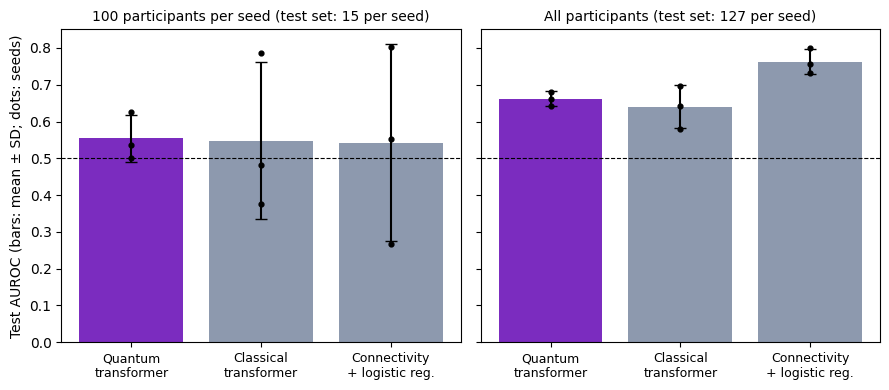

In [16]:
labels = {"quantum": "Quantum\ntransformer", "small_transformer": "Classical\ntransformer",
          "fc_logreg": "Connectivity\n+ logistic reg."}
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
for ax, (title, setting) in zip(axes, [("100 participants per seed", "n100"), ("All participants", "all")]):
    df = RESULTS[RESULTS.setting == setting]
    s = summary(df)
    colors = ["#7b2cbf" if m == "quantum" else "#8d99ae" for m in s.index]
    ax.bar(range(len(s)), s["test_auroc_mean"], yerr=s["test_auroc_sd"], color=colors, capsize=4)
    for i, m in enumerate(s.index):
        pts = df.loc[df["model"] == m, "test_auroc"]
        ax.scatter([i] * len(pts), pts, color="k", s=12, zorder=3)
    ax.axhline(0.5, color="k", lw=0.8, ls="--")
    ax.set_xticks(range(len(s))); ax.set_xticklabels([labels[m] for m in s.index], fontsize=9)
    ax.set_title(f"{title} (test set: {int(s['test_participants_per_seed'].iloc[0])} per seed)", fontsize=10)
axes[0].set_ylabel("Test AUROC (bars: mean ± SD; dots: seeds)")
plt.tight_layout(); plt.savefig("abide_results.png", dpi=300, bbox_inches="tight"); plt.show()

## 9. How to read these results

**With 100 participants, no model can be told apart from any other.** Each seed tests on only 15 people, so one person's prediction moves the AUROC a lot: the connectivity model, for example, scores 0.80, 0.55 and 0.27 on the three seeds, depending on which 100 people were drawn. A claim that one model is better "in small samples" cannot be tested at this size, whichever model is quantum.

**With all 846 participants (127 tested per seed):**
- The quantum time-series transformer reaches AUROC 0.662 ± 0.020 and the classical transformer of the same size 0.640 ± 0.058. The difference is within the spread across seeds: at matched size, the quantum model behaves like its classical counterpart.
- The best model is the simplest, standard neuroscience approach: functional connectivity + logistic regression, AUROC 0.762 ± 0.034 with the same number of parameters. Which regions fluctuate together carries more diagnostic information here than the detailed time course, consistent with earlier ABIDE work (Abraham et al., 2017).
- Simulating the quantum model costs about 15 minutes per training run on a CPU, against seconds for the classical models.

**Limits of this demonstration.** Three seeds, one random train/validation/test split per seed (participants from the same site can appear in training and test, so site differences may contribute), and fixed, untuned training settings for the neural models.

**Take-home.** Quantum machine learning models can be trained on real brain data with standard tools today. Whether they help must be shown against classical models of the same size and against the established methods of the field, with test sets large enough to separate real differences from chance.

Abraham, A., Milham, M. P., Di Martino, A., Craddock, R. C., Samaras, D., Thirion, B., & Varoquaux, G. (2017). Deriving reproducible biomarkers from multi-site resting-state data: An autism-based example. *NeuroImage, 147*, 736–745. https://doi.org/10.1016/j.neuroimage.2016.10.045

Sim, S., Johnson, P. D., & Aspuru-Guzik, A. (2019). Expressibility and entangling capability of parameterized quantum circuits for hybrid quantum-classical algorithms. *Advanced Quantum Technologies, 2*(12), 1900070.